1. Configuração e conexão
Execute este notebook a partir da raiz do projeto ou da pasta analysis/. Ele reutiliza a configuração de conexão do PostgresRepository e as credenciais do .env existente. O PostgreSQL do Docker precisa estar ativo.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from psycopg.rows import dict_row
from IPython.display import Markdown, display

# Encontra a raiz do projeto mesmo se o kernel iniciar em analysis/.
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "storage" / "postgres_repository.py").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Abra o notebook dentro do projeto ETL-Combustiveis.")

sys.path.insert(0, str(project_root))
from src.storage.postgres_repository import PostgresRepository

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (10, 5)

repository = PostgresRepository()
print(f"Projeto: {project_root}")


Projeto: c:\Users\Caio\Desktop\ETL-Combustiveis


2. Extração dos dados da Gold
Usamos a tabela fato e as dimensões para obter observações individuais. Isso permite explorar distribuições e criar agrupamentos diferentes daqueles já disponibilizados pelas views da Gold.

In [2]:
query = """
SELECT
    f.data_coleta,
    l.regiao,
    l.uf,
    l.municipio,
    c.nome AS combustivel,
    c.unidade_medida,
    f.preco_venda,
    f.revenda_id
FROM gold.fato_preco f
JOIN gold.dim_localidade l ON l.id = f.localidade_id
JOIN gold.dim_combustivel c ON c.id = f.combustivel_id
"""

with psycopg.connect(**repository.connection_params, row_factory=dict_row) as conn:
    with conn.cursor() as cursor:
        cursor.execute(query)
        df = pd.DataFrame(cursor.fetchall())

if df.empty:
    raise ValueError("A tabela Gold nao possui registros.")

df["data_coleta"] = pd.to_datetime(df["data_coleta"])
df["preco_venda"] = df["preco_venda"].astype(float)
df["mes"] = df["data_coleta"].dt.to_period("M").dt.to_timestamp()

display(df.head())


,data_coleta,regiao,uf,municipio,combustivel,unidade_medida,preco_venda,revenda_id,mes
0,2025-01-15,N,AC,CRUZEIRO DO SUL,ETANOL,R$ / litro,5.590,435,2025-01-01
1,2025-01-15,N,AC,CRUZEIRO DO SUL,DIESEL S10,R$ / litro,7.930,435,2025-01-01
2,2025-01-15,N,AC,CRUZEIRO DO SUL,DIESEL,R$ / litro,7.930,435,2025-01-01
3,2025-01-15,N,AC,CRUZEIRO DO SUL,GASOLINA ADITIVADA,R$ / litro,7.730,435,2025-01-01
4,2025-01-15,N,AC,CRUZEIRO DO SUL,GASOLINA,R$ / litro,7.730,435,2025-01-01


3. Visão geral da base
Verificamos a cobertura temporal, o número de UFs, combustíveis e observações.

In [3]:
resumo = pd.DataFrame([{
    "total_coletas": len(df),
    "ufs": df["uf"].nunique(),
    "combustiveis": df["combustivel"].nunique(),
    "data_inicial": df["data_coleta"].min().date(),
    "data_final": df["data_coleta"].max().date(),
}])
display(resumo)

display(
    df.groupby("combustivel", as_index=False)
      .agg(coletas=("preco_venda", "size"), postos=("revenda_id", "nunique"))
      .sort_values("coletas", ascending=False)
)


,total_coletas,ufs,combustiveis,data_inicial,data_final
0,420409,27,6,2025-01-01,2025-06-30


,combustivel,coletas,postos
3,GASOLINA,110818,7654
2,ETANOL,92598,6658
4,GASOLINA ADITIVADA,85580,6136
1,DIESEL S10,76134,5724
0,DIESEL,45771,3330
5,GNV,9508,631


4. Evolução mensal dos preços
Agrupamos por mês e combustível, calculando média, mínimo, máximo, quantidade de coletas e número de postos distintos. O gráfico compara apenas gasolina e etanol, ambos vendidos por litro.

C:\Users\Caio\AppData\Local\Temp\ipykernel_14764\1952598784.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(mensal.round(3))


,mes,combustivel,unidade_medida,preco_medio,preco_minimo,preco_maximo,total_coletas,postos_pesquisados
0,2025-01-01,DIESEL,R$ / litro,6.131,5.390,7.930,7463,2425
1,2025-01-01,DIESEL S10,R$ / litro,6.186,5.190,8.990,12317,4061
2,2025-01-01,ETANOL,R$ / litro,4.369,3.290,6.160,14921,4864
3,2025-01-01,GASOLINA,R$ / litro,6.184,5.040,8.290,17793,5707
4,2025-01-01,GASOLINA ADITIVADA,R$ / litro,6.379,5.430,9.490,13795,4508
5,2025-01-01,GNV,R$ / m³,4.821,3.790,6.490,1527,484
6,2025-02-01,DIESEL,R$ / litro,6.429,5.580,8.190,7060,2426
7,2025-02-01,DIESEL S10,R$ / litro,6.479,5.540,8.990,11674,4086
8,2025-02-01,ETANOL,R$ / litro,4.546,3.390,6.490,14164,4881
9,2025-02-01,GASOLINA,R$ / litro,6.367,5.190,8.790,17015,5772


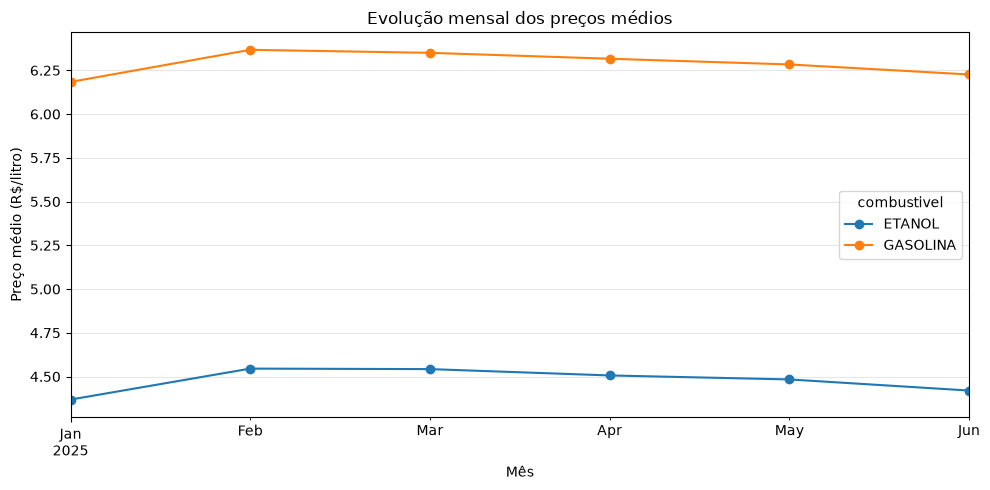

In [4]:
mensal = (
    df.groupby(["mes", "combustivel", "unidade_medida"], as_index=False)
      .agg(
          preco_medio=("preco_venda", "mean"),
          preco_minimo=("preco_venda", "min"),
          preco_maximo=("preco_venda", "max"),
          total_coletas=("preco_venda", "size"),
          postos_pesquisados=("revenda_id", "nunique"),
      )
      .sort_values(["mes", "combustivel"])
)
display(mensal.round(3))

comparacao = mensal[mensal["combustivel"].isin(["GASOLINA", "ETANOL"])]
serie = comparacao.pivot(index="mes", columns="combustivel", values="preco_medio")
ax = serie.plot(marker="o", figsize=(10, 5))
ax.set(title="Evolução mensal dos preços médios", xlabel="Mês", ylabel="Preço médio (R$/litro)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


5. Ranking de preços de gasolina por UF
Usamos o último mês disponível na base. Mostramos também a quantidade de coletas, pois os tamanhos das amostras diferem muito entre estados.

Mês de referência: 06/2025
5 maiores preços médios:


,preco_medio,coletas,postos
uf,,,
AC,7.794,59,18
AM,7.241,241,62
RR,6.952,72,16
RO,6.869,199,60
SE,6.587,173,41


5 menores preços médios:


,preco_medio,coletas,postos
uf,,,
PI,5.904,258,94
PB,6.053,288,73
AP,6.062,68,17
SP,6.075,5446,1540
ES,6.083,419,118


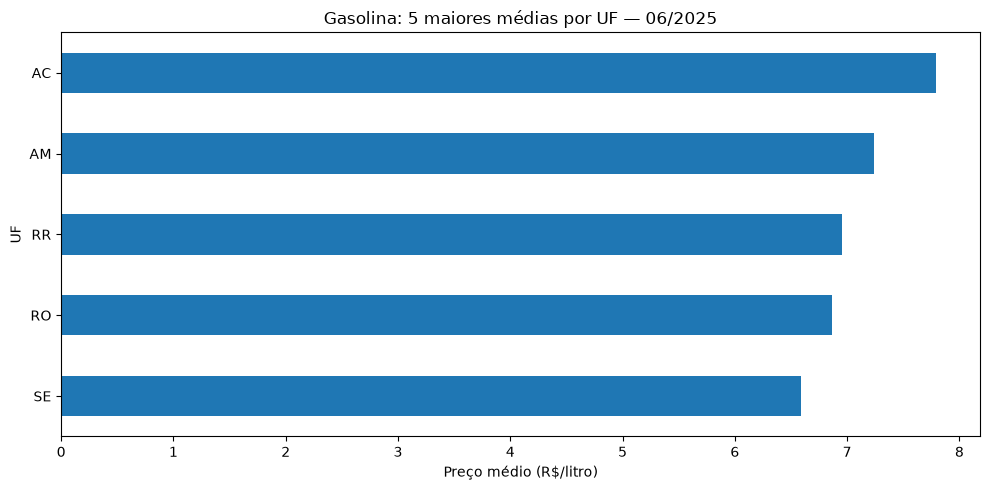

In [5]:
gasolina = df.loc[df["combustivel"] == "GASOLINA"].copy()
ultimo_mes = gasolina["mes"].max()

ranking = (
    gasolina.loc[gasolina["mes"] == ultimo_mes]
    .groupby("uf")
    .agg(preco_medio=("preco_venda", "mean"), coletas=("preco_venda", "size"),
         postos=("revenda_id", "nunique"))
    .sort_values("preco_medio", ascending=False)
)

print(f"Mês de referência: {ultimo_mes:%m/%Y}")
print("5 maiores preços médios:")
display(ranking.head(5).round(3))
print("5 menores preços médios:")
display(ranking.tail(5).sort_values("preco_medio").round(3))

ax = ranking.head(5).sort_values("preco_medio")["preco_medio"].plot.barh()
ax.set(title=f"Gasolina: 5 maiores médias por UF — {ultimo_mes:%m/%Y}",
       xlabel="Preço médio (R$/litro)", ylabel="UF")
plt.tight_layout()
plt.show()


6. Variação da gasolina no semestre
Comparamos o primeiro e o último mês observados. Isso mede a variação da média das coletas, não necessariamente a variação enfrentada por um consumidor ou posto específico.

In [6]:
evolucao_gasolina = (
    gasolina.groupby("mes")["preco_venda"].mean().sort_index()
)
preco_inicial = evolucao_gasolina.iloc[0]
preco_final = evolucao_gasolina.iloc[-1]
variacao_pct = (preco_final / preco_inicial - 1) * 100

print(f"Média inicial: R$ {preco_inicial:.3f}")
print(f"Média final:   R$ {preco_final:.3f}")
print(f"Variação:      {variacao_pct:+.2f}%")
display(evolucao_gasolina.rename("preco_medio").to_frame().round(3))


Média inicial: R$ 6.184
Média final:   R$ 6.226
Variação:      +0.69%


,preco_medio
mes,
2025-01-01,6.184
2025-02-01,6.367
2025-03-01,6.350
2025-04-01,6.316
2025-05-01,6.284
2025-06-01,6.226


7. Distribuição e dispersão dos preços
O histograma mostra onde se concentram as observações de gasolina. A estatística descritiva permite comparar média, mediana, quartis e extremos. Preços muito altos ou baixos não são automaticamente erros.

,gasolina_R$/litro
count,110818.000
mean,6.288
std,0.405
min,4.990
25%,5.990
50%,6.280
75%,6.490
max,8.990


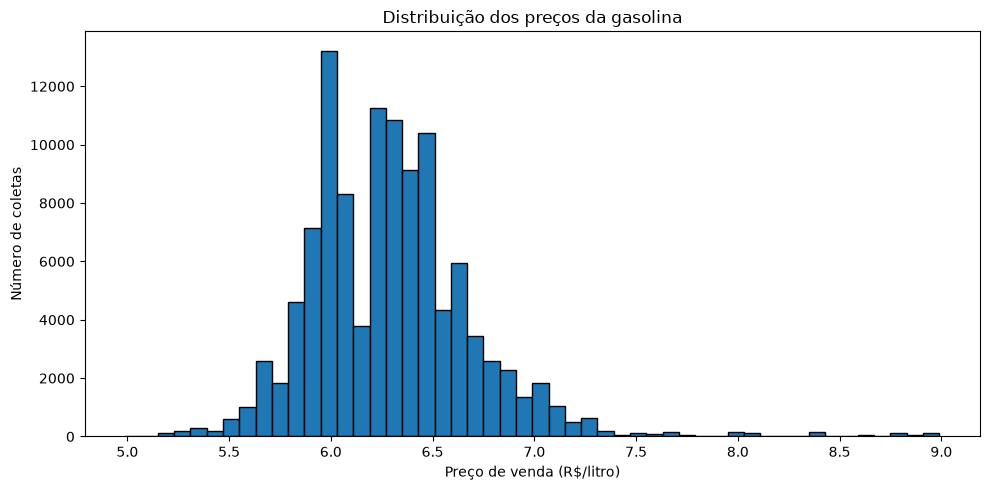

In [7]:
display(gasolina["preco_venda"].describe().to_frame(name="gasolina_R$/litro").round(3))

ax = gasolina["preco_venda"].plot.hist(bins=50, edgecolor="black")
ax.set(title="Distribuição dos preços da gasolina", xlabel="Preço de venda (R$/litro)",
       ylabel="Número de coletas")
plt.tight_layout()
plt.show()


8. Síntese automática dos insights
Os textos abaixo são calculados a partir da consulta atual, para continuarem corretos quando a Gold receber novos períodos.

In [8]:
maior_uf = ranking.iloc[0]
menor_uf = ranking.iloc[-1]
maior_sigla = ranking.index[0]
menor_sigla = ranking.index[-1]
diferenca = maior_uf["preco_medio"] - menor_uf["preco_medio"]
mediana = gasolina["preco_venda"].median()
media = gasolina["preco_venda"].mean()

display(Markdown(f"""
### Principais achados

- **Cobertura:** {len(df):,} observações, {df['uf'].nunique()} UFs e {df['combustivel'].nunique()} combustíveis.
- **Evolução da gasolina:** a média das coletas passou de **R$ {preco_inicial:.3f}** para **R$ {preco_final:.3f}** ({variacao_pct:+.2f}%) entre o primeiro e o último mês.
- **Desigualdade regional ({ultimo_mes:%m/%Y}):** **{maior_sigla}** apresentou a maior média (**R$ {maior_uf['preco_medio']:.3f}**, {int(maior_uf['coletas'])} coletas), enquanto **{menor_sigla}** apresentou a menor (**R$ {menor_uf['preco_medio']:.3f}**, {int(menor_uf['coletas'])} coletas). Diferença: **R$ {diferenca:.3f}/litro**.
- **Distribuição da gasolina:** média de **R$ {media:.3f}** e mediana de **R$ {mediana:.3f}**.

**Limitação:** diferenças no número e na composição das coletas podem afetar rankings e tendências. Os resultados descrevem a amostra de preços da ANP, não uma média ponderada por consumo.
"""))



### Principais achados

- **Cobertura:** 420,409 observações, 27 UFs e 6 combustíveis.
- **Evolução da gasolina:** a média das coletas passou de **R$ 6.184** para **R$ 6.226** (+0.69%) entre o primeiro e o último mês.
- **Desigualdade regional (06/2025):** **AC** apresentou a maior média (**R$ 7.794**, 59 coletas), enquanto **PI** apresentou a menor (**R$ 5.904**, 258 coletas). Diferença: **R$ 1.890/litro**.
- **Distribuição da gasolina:** média de **R$ 6.288** e mediana de **R$ 6.280**.

**Limitação:** diferenças no número e na composição das coletas podem afetar rankings e tendências. Os resultados descrevem a amostra de preços da ANP, não uma média ponderada por consumo.
